### Data preprocessing

In [ ]:
#DepMap data extraction from Celligner data
import os
input_file = "E:/TCGA alighned/Celligner_aligned_data.csv" #Big file, so read line by line
#Download from https://figshare.com/articles/dataset/Celligner_data/11965269/4

output_file = "../data/Depmap_aligned.csv" #Smaller file with only DepMap samples
if not os.path.exists(output_file):
    n = 0
    with open(input_file, "r", encoding="utf-8") as infile, \
        open(output_file, "w", encoding="utf-8") as outfile:
        header = infile.readline()
        outfile.write(header)
        for line in infile:
            if line.startswith("\"ACH-"):
                outfile.write(line)
                n += 1
    print(f"Extracted {n} lines to {output_file}")
else:
    print(f"{output_file} already exists, skipping extraction") 

../data/Depmap_aligned.csv already exists, skipping extraction


In [44]:
import pandas as pd
import numpy as np
trimap = pd.read_csv("../trimap_hippo_260904.csv", index_col=0)
cluster = pd.read_csv("../cluster_hippo_260904.csv",index_col=0)
trimap = trimap.join(cluster)

In [45]:
import pandas as pd
import numpy as np
from sklearn.svm import SVC

df = trimap.copy()
X = df[['0', '1']].values
y = df['Cluster'].values
clf = SVC(kernel='rbf', probability=True, gamma='scale', random_state=0)
clf.fit(X, y)
proba = clf.predict_proba(X)
confidence = proba.max(axis=1)
threshold = 0.9  # adjust as needed
mask_far = confidence >= threshold
far_samples = df[mask_far]
print(far_samples)


                   0         1  Cluster
DepMap_ID                              
ACH-000001 -0.225297 -0.243885        1
ACH-000004 -1.634339 -2.143422        0
ACH-000005 -1.570878 -1.811395        0
ACH-000007 -0.831338 -1.039475        1
ACH-000011  1.657401  0.293753        4
...              ...       ...      ...
ACH-002710  1.733152  0.186036        4
ACH-002785  0.675169  1.170904        3
ACH-002800  0.849088  0.608157        3
ACH-002847  1.692856  0.270930        4
ACH-002926 -0.759510 -0.249971        1

[781 rows x 3 columns]


In [100]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df_exp = pd.read_csv("../data/Depmap_aligned.csv",index_col=0) 
cluster = pd.read_csv("../cluster_hippo.csv",index_col=0)
clusterdic = {id: cluster.loc[id,"Cluster"] for id in cluster.index}

keep_samples = df_exp.index.intersection(cluster.index).intersection(far_samples.index)
df_exp_dep = df_exp.loc[keep_samples].copy()

df_exp_dep = df_exp_dep.dropna(axis=1, how="any")
df_exp_dep = df_exp_dep.loc[:, df_exp_dep.std() != 0]
df_exp_dep[:] = StandardScaler().fit_transform(df_exp_dep)

In [101]:
info = pd.read_csv("../data/Celligner_info.csv")
id_to_lineage = {id:lin for id, lin in zip(info["sampleID"], info["lineage"])}
id_to_subtype = {id:f'{lin}_{sub}' for id, lin, sub in zip(info["sampleID"], info["lineage"], info["subtype"])}
from sklearn.feature_selection import SelectKBest, f_classif
import numpy as np
df_exp_dep2 = df_exp_dep.copy()
X_gene = df_exp_dep2.values
# add lineage columns
lineage_cols = []

for lin in set(id_to_lineage.values()):
    df_exp_dep2[lin] = [1 if id_to_lineage[d]==lin else 0 for d in df_exp_dep2.index]
    if sum(df_exp_dep2[lin]) < 10:
       df_exp_dep2.drop(columns=lin, inplace=True)
    else:
        lineage_cols.append(lin)

for sub in set(id_to_subtype.values()):
    df_exp_dep2[sub] = [1 if id_to_subtype[d]==sub else 0 for d in df_exp_dep2.index]
    if sum(df_exp_dep2[sub]) < 10:
        df_exp_dep2.drop(columns=sub, inplace=True)
    else:
        lineage_cols.append(sub)

X_lineage = df_exp_dep2[lineage_cols].values
y = np.array([clusterdic[d] for d in df_exp_dep2.index])

In [73]:
#Feature selection
from sklearn.feature_selection import f_classif
from itertools import combinations
import numpy as np

selected = set()
a = []

for cls1, cls2 in combinations(np.unique(y), 2):
    mask = np.isin(y, [cls1, cls2])
    X_sub = X_gene[mask]
    y_sub = y[mask]
    y_bin = (y_sub == cls2).astype(int)
    f_vals, _ = f_classif(X_sub, y_bin)
    top = np.argsort(np.nan_to_num(f_vals))[-30:]
    selected.update(top)
    a.append(top)
    
X_gene_reduced = X_gene[:, sorted(selected)]
chosen_genes = df_exp_dep.columns.values[sorted(selected)]
X_reduced = np.hstack([X_gene_reduced, X_lineage])

In [ ]:
#X_reduced = np.save("../data/X_reduced_clinical_260919.npy", X_reduced)
#chosen_genes = np.save("../data/chosen_genes_clinical_260919.npy", chosen_genes)
#X_lineage = np.save("../data/X_lineage_clinical_260919.npy", X_lineage)
#y = np.save("../data/y_clinical_260919.npy", y)
#np.save("../data/lineage_cols.npy", lineage_cols)

### Data loading

In [46]:
import numpy as np
X_reduced = np.load("../data/X_reduced_clinical_260919.npy") #Expression + lineage
X_lineage = np.load("../data/X_lineage_clinical_260919.npy") #Lineage only
chosen_genes = np.load("../data/chosen_genes_clinical_260919.npy", allow_pickle=True)
y = np.load("../data/y_clinical_260919.npy")
lineage_cols = np.load("../data/lineage_cols.npy", allow_pickle=True)


### Bayesian optimization

In [ ]:
#XGBoost Bayesian Optimization
import pandas as pd
import numpy as np
import warnings
from sklearn.datasets import make_classification  # Using this to create sample data
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, make_scorer

# --- New Imports for Bayesian Optimization ---
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=0)),
    ('model', XGBClassifier(use_label_encoder=False, 
                            eval_metric='mlogloss', 
                            random_state=42, 
                            n_jobs=-1))
])

def print_bal_acc(y_true, y_pred):
    score = balanced_accuracy_score(y_true, y_pred)
    print(f"Balanced Accuracy: {score:.4f}")
    return score

scorer = make_scorer(print_bal_acc, greater_is_better=True)

search_space = {
    'model__learning_rate': Real(0.01, 0.3, 'log-uniform'),
    'model__max_depth': Integer(2, 6),
    'model__subsample': Real(0.2, 1.0, 'uniform'),
    'model__colsample_bytree': Real(0.2, 1.0, 'uniform'),
    'model__reg_lambda': Real(0.1, 10.0, 'log-uniform'),  # L2 regularization
    'model__reg_alpha': Real(0.0, 5.0, 'uniform'),        # L1 regularization
    'model__gamma': Real(1, 10.0, 'uniform'),
    'model__n_estimators': Integer(100, 300)
}

# --- 4. Set up BayesSearchCV ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# We'll optimize for 'balanced_accuracy'
opt = BayesSearchCV(
    estimator=pipeline,
    search_spaces=search_space,
    n_iter=100,  # Number of parameter settings to try
    scoring=scorer,
    cv=cv,
    n_jobs=1,  # Use all available cores
    random_state=0,
    verbose=0   # Set to 1 or 2 for more output
)

# --- 5. Run the Optimization ---
print("Running Bayesian Optimization...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    opt.fit(X_reduced, y)

# --- 6. Show the Results ---
print("\n--- Optimization Complete ---")
print(f"Best parameters found:\n{opt.best_params_}")
print(f"\nBest 5-fold CV Balanced Accuracy: {opt.best_score_:.4f}")

df_results = pd.DataFrame(opt.cv_results_)
df_results = df_results.sort_values(by='mean_test_score', ascending=False)

print("\nTop 5 results from the optimization search:")
print(df_results[['params', 'mean_test_score', 'std_test_score']].head())

In [ ]:
import pandas as pd
import numpy as np
import warnings
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, make_scorer
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# --- Define pipeline ---
pipeline_lr = Pipeline([
    ('smote', SMOTETomek(random_state=0)),
    ('model', LogisticRegression(
        solver='saga',        # supports L1/L2 penalties
        max_iter=4000,
        random_state=42,
        n_jobs=-1
    ))
])

# --- Custom scorer ---
def print_bal_acc(y_true, y_pred):
    score = balanced_accuracy_score(y_true, y_pred)
    print(f"Balanced Accuracy: {score:.4f}")
    return score

scorer = make_scorer(print_bal_acc, greater_is_better=True)

# --- Search space ---
search_space_lr = {
    'model__penalty': Categorical(['l1', 'l2', 'elasticnet', None]),
    'model__C': Real(1e-3, 1e+2, prior='log-uniform'),   # inverse regularization strength
    'model__l1_ratio': Real(0.0, 1.0, prior='uniform'),  # only used if penalty='elasticnet'
}

# --- Cross-validation ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# --- BayesSearchCV setup ---
opt_lr = BayesSearchCV(
    estimator=pipeline_lr,
    search_spaces=search_space_lr,
    n_iter=100,
    scoring=scorer,
    cv=cv,
    n_jobs=1,
    random_state=0,
    verbose=0a
)

# --- Run the optimization ---
print("Running Bayesian Optimization (Logistic Regression)...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    opt_lr.fit(X_reduced, y)

# --- Results ---
print("\n--- Optimization Complete ---")
print(f"Best parameters found:\n{opt_lr.best_params_}")
print(f"\nBest 5-fold CV Balanced Accuracy: {opt_lr.best_score_:.4f}")

df_results_lr = pd.DataFrame(opt_lr.cv_results_).sort_values(
    by='mean_test_score', ascending=False)
print("\nTop 5 results from the optimization search:")
print(df_results_lr[['params', 'mean_test_score', 'std_test_score']].head())


In [ ]:
import pandas as pd
import numpy as np
import warnings
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, make_scorer
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# --- Define pipeline ---
pipeline_rf = Pipeline([
    ('smote', SMOTETomek(random_state=0)),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# --- Custom scorer ---
def print_bal_acc(y_true, y_pred):
    score = balanced_accuracy_score(y_true, y_pred)
    print(f"Balanced Accuracy: {score:.4f}")
    return score

scorer = make_scorer(print_bal_acc, greater_is_better=True)

# --- Search space for Random Forest ---
search_space_rf = {
    'model__n_estimators': Integer(100, 500),
    'model__max_depth': Integer(2, 20),
    'model__min_samples_split': Integer(2, 20),
    'model__min_samples_leaf': Integer(1, 10),
    'model__max_features': Real(0.3, 1.0, prior='uniform'),
    'model__bootstrap': Categorical([True, False]),
    'model__criterion': Categorical(['gini', 'entropy', 'log_loss'])
}

# --- Cross-validation ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# --- BayesSearchCV setup ---
opt_rf = BayesSearchCV(
    estimator=pipeline_rf,
    search_spaces=search_space_rf,
    n_iter=100,
    scoring=scorer,
    cv=cv,
    n_jobs=1,    # set = -1 if you don't need print() output
    random_state=0,
    verbose=0
)

# --- Run the optimization ---
print("Running Bayesian Optimization (Random Forest)...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    opt_rf.fit(X_reduced, y)

# --- Results ---
print("\n--- Optimization Complete ---")
print(f"Best parameters found:\n{opt_rf.best_params_}")
print(f"\nBest 5-fold CV Balanced Accuracy: {opt_rf.best_score_:.4f}")

df_results_rf = pd.DataFrame(opt_rf.cv_results_).sort_values(
    by='mean_test_score', ascending=False)

print("\nTop 5 results from the optimization search:")
print(df_results_rf[['params', 'mean_test_score', 'std_test_score']].head())


In [ ]:
import pandas as pd
import numpy as np
import warnings
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, make_scorer
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# --- Define pipeline ---
pipeline_svm = Pipeline([
    ('smote', SMOTETomek(random_state=0)),
    ('model', SVC(probability=True, random_state=42))
])

# --- Custom scorer ---
def print_bal_acc(y_true, y_pred):
    score = balanced_accuracy_score(y_true, y_pred)
    print(f"Balanced Accuracy: {score:.4f}")
    return score

scorer = make_scorer(print_bal_acc, greater_is_better=True)

# --- Search space for SVM ---
# You can tune kernel type, C, gamma, and degree (for poly)
search_space_svm = {
    'model__kernel': Categorical(['linear', 'rbf', 'poly', 'sigmoid']),
    'model__C': Real(1e-3, 1e+3, prior='log-uniform'),
    'model__gamma': Real(1e-4, 1e-1, prior='log-uniform'),
    'model__degree': Integer(2, 5),  # only used for 'poly'
    'model__coef0': Real(0.0, 1.0, prior='uniform')  # affects 'poly' and 'sigmoid'
}

# --- Cross-validation ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# --- BayesSearchCV setup ---
opt_svm = BayesSearchCV(
    estimator=pipeline_svm,
    search_spaces=search_space_svm,
    n_iter=100,
    scoring=scorer,
    cv=cv,
    n_jobs=1,    # use -1 for full parallel, but print() may disappear
    random_state=0,
    verbose=0
)

# --- Run the optimization ---
print("Running Bayesian Optimization (SVM)...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    opt_svm.fit(X_reduced, y)

# --- Results ---
print("\n--- Optimization Complete ---")
print(f"Best parameters found:\n{opt_svm.best_params_}")
print(f"\nBest 5-fold CV Balanced Accuracy: {opt_svm.best_score_:.4f}")

df_results_svm = pd.DataFrame(opt_svm.cv_results_).sort_values(
    by='mean_test_score', ascending=False)

print("\nTop 5 results from the optimization search:")
print(df_results_svm[['params', 'mean_test_score', 'std_test_score']].head())


In [ ]:
import pandas as pd

output_path = '../result/optimized_results_1vs1f.xlsx'

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    df_results.to_excel(writer, sheet_name='Results_XGB', index=False)
    df_results_lr.to_excel(writer, sheet_name='Results_LR', index=False)
    df_results_rf.to_excel(writer, sheet_name='Results_RF', index=False)
    df_results_svm.to_excel(writer, sheet_name='Results_SVM', index=False)

print(f"Results saved to: {output_path}")

### Comparing models (Fig. S16a-c)

In [47]:
#Fig. S16a
import pandas as pd
import numpy as np
import warnings
from collections import OrderedDict

from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score
)

param_lr = OrderedDict([
    ('C', 0.0664766463481814),
    ('l1_ratio', 0.6930832705251627),
    ('penalty', 'l1')
])

param_rf = OrderedDict([
    ('bootstrap', True),
    ('criterion', 'entropy'),
    ('max_depth', 10),
    ('max_features', 0.5575631887599894),
    ('min_samples_leaf', 10),
    ('min_samples_split', 2),
    ('n_estimators', 500)
])

param_svm = OrderedDict([
    ('C', 11.726971104705752),
    ('coef0', 1.0),
    ('degree', 2),
    ('gamma', 0.0005859744883560911),
    ('kernel', 'rbf')
])

param_xgb = OrderedDict([
    ('colsample_bytree', 1.0),
    ('gamma', 1.0),
    ('learning_rate', 0.044467427955017326),
    ('max_depth', 4),
    ('n_estimators', 100),
    ('reg_alpha', 5.0),
    ('reg_lambda', 0.31039965058000984),
    ('subsample', 0.7128060642323459)
])

models = {
    "LogisticRegression": LogisticRegression(
        solver='saga',
        max_iter=10000,
        random_state=42,
        n_jobs=-1,
        **param_lr
    ),
    "RandomForest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        **param_rf
    ),
    "XGBoost": XGBClassifier(
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1,
        **param_xgb
    ),
    "SVM": SVC(
        probability=True,
        random_state=42,
        **param_svm
    )
}

results = []
raw_val = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    for name, model in models.items():
        print(f"\nModel: {name}")

        acc_train, acc_val = [], []
        bal_train, bal_val = [], []
        precision_hs, recall_hs = [], []

        for train_idx, val_idx in cv.split(X_reduced, y):
            X_train, X_val = X_reduced[train_idx], X_reduced[val_idx]
            y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

            pipeline = Pipeline([
                ('smote', SMOTETomek(random_state=0)),
                ('model', model)
            ])

            pipeline.fit(X_train, y_train)

            y_pred_train = pipeline.predict(X_train)
            y_pred_val = pipeline.predict(X_val)

            acc_train.append(accuracy_score(y_train, y_pred_train))
            acc_val.append(accuracy_score(y_val, y_pred_val))
            bal_train.append(balanced_accuracy_score(y_train, y_pred_train))
            bal_val.append(balanced_accuracy_score(y_val, y_pred_val))

            precision_hs.append(
                precision_score(
                    y_val, y_pred_val,
                    labels=[4],
                    average=None,
                    zero_division=0
                )[0]
            )

            recall_hs.append(
                recall_score(
                    y_val, y_pred_val,
                    labels=[4],
                    average=None,
                    zero_division=0
                )[0]
            )

        print(f" Train Acc: {np.mean(acc_train):.3f} | Val Acc: {np.mean(acc_val):.3f}")
        print(f" Train BalAcc: {np.mean(bal_train):.3f} | Val BalAcc: {np.mean(bal_val):.3f}")
        print(f" Hippo-strong Precision: {np.mean(precision_hs):.3f} ± {np.std(precision_hs):.3f}")
        print(f" Hippo-strong Recall: {np.mean(recall_hs):.3f} ± {np.std(recall_hs):.3f}")
        raw_val[name] = bal_val
        results.append({
            "Method": name,
            "Train Accuracy": np.mean(acc_train),
            "Val Accuracy": np.mean(acc_val),
            "Train Balanced Acc": np.mean(bal_train),
            "Val Balanced Acc": np.mean(bal_val),
            "Val Balanced Acc SD": np.std(bal_val),
            "Hippo-strong Precision": np.mean(precision_hs),
            "Hippo-strong Precision SD": np.std(precision_hs),
            "Hippo-strong Recall": np.mean(recall_hs),
            "Hippo-strong Recall SD": np.std(recall_hs)
        })

results_df = pd.DataFrame(results)
results_df


Model: LogisticRegression
 Train Acc: 0.728 | Val Acc: 0.667
 Train BalAcc: 0.766 | Val BalAcc: 0.699
 Hippo-strong Precision: 0.394 ± 0.070
 Hippo-strong Recall: 0.667 ± 0.139

Model: RandomForest
 Train Acc: 0.920 | Val Acc: 0.680
 Train BalAcc: 0.929 | Val BalAcc: 0.700
 Hippo-strong Precision: 0.462 ± 0.039
 Hippo-strong Recall: 0.617 ± 0.100

Model: XGBoost
 Train Acc: 0.903 | Val Acc: 0.671
 Train BalAcc: 0.916 | Val BalAcc: 0.685
 Hippo-strong Precision: 0.453 ± 0.040
 Hippo-strong Recall: 0.550 ± 0.041

Model: SVM
 Train Acc: 0.858 | Val Acc: 0.652
 Train BalAcc: 0.880 | Val BalAcc: 0.673
 Hippo-strong Precision: 0.423 ± 0.051
 Hippo-strong Recall: 0.617 ± 0.085


,Method,Train Accuracy,Val Accuracy,Train Balanced Acc,Val Balanced Acc,Val Balanced Acc SD,Hippo-strong Precision,Hippo-strong Precision SD,Hippo-strong Recall,Hippo-strong Recall SD
0,LogisticRegression,0.727758,0.666689,0.765971,0.698649,0.042733,0.394337,0.070450,0.666667,0.139443
1,RandomForest,0.919684,0.680189,0.929203,0.700198,0.011766,0.462233,0.038502,0.616667,0.100000
2,XGBoost,0.903472,0.671189,0.916215,0.685307,0.019310,0.453214,0.040159,0.550000,0.040825
3,SVM,0.857843,0.651515,0.879859,0.673205,0.032216,0.423208,0.051208,0.616667,0.084984


In [51]:

# Fig. S16a
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score

y = np.asarray(y)
X_lineage = np.asarray(X_lineage)
idx = np.where(chosen_genes == 'ENSG00000166741')[0][0]
X_nnmt = X_reduced[:, idx].reshape(-1, 1)
X_lineage_nnmt = np.column_stack([X_lineage, X_nnmt])

Xs = {"Lineage only": X_lineage, "Lineage + NNMT": X_lineage_nnmt}
results = {name: {"BalAcc": [], "Precision_HS": [], "Recall_HS": []} for name in Xs}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for name, X in Xs.items():
    for train_idx, val_idx in cv.split(X, y):
        model = Pipeline([
            ("scale", StandardScaler()),
            ("LR", LogisticRegression(class_weight="balanced", max_iter=2000))
        ])

        model.fit(X[train_idx], y[train_idx])
        pred = model.predict(X[val_idx])
        y_val = y[val_idx]

        results[name]["BalAcc"].append(balanced_accuracy_score(y_val, pred))
        results[name]["Precision_HS"].append(
            precision_score(y_val, pred, labels=[4], average=None, zero_division=0)[0]
        )
        results[name]["Recall_HS"].append(
            recall_score(y_val, pred, labels=[4], average=None, zero_division=0)[0]
        )

    raw_val[name] = results[name]["BalAcc"].copy()

    print(f"\n{name}")
    for metric, values in results[name].items():
        values = np.asarray(values)
        print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

print("\nRaw Balanced Accuracy:")
print(raw_val)



Lineage only
BalAcc: 0.511 ± 0.019
Precision_HS: 0.176 ± 0.029
Recall_HS: 0.417 ± 0.139

Lineage + NNMT
BalAcc: 0.519 ± 0.018
Precision_HS: 0.194 ± 0.050
Recall_HS: 0.450 ± 0.125

Raw Balanced Accuracy:
{'LogisticRegression': [np.float64(0.6261666666666666), np.float64(0.7321515151515151), np.float64(0.7387529137529139), np.float64(0.6741538461538462), np.float64(0.7220192307692307)], 'RandomForest': [np.float64(0.6906666666666667), np.float64(0.7199300699300698), np.float64(0.7001748251748252), np.float64(0.6861602564102565), np.float64(0.7040576923076923)], 'XGBoost': [np.float64(0.6815), np.float64(0.6882867132867133), np.float64(0.7025641025641025), np.float64(0.7036282051282051), np.float64(0.6505576923076923)], 'SVM': [np.float64(0.6866666666666668), np.float64(0.6716200466200466), np.float64(0.6894941724941724), np.float64(0.6125192307692308), np.float64(0.705724358974359)], 'Lineage only': [np.float64(0.5337500000000001), np.float64(0.5302121212121211), np.float64(0.5022564102

In [60]:
rng = np.random.default_rng(0)
raw_val["Random choice"] = []

for _, val_idx in cv.split(X_lineage, y):
    pred = rng.choice(np.unique(y), size=len(val_idx))
    raw_val["Random choice"].append(balanced_accuracy_score(y[val_idx], pred))


0.687995711264499


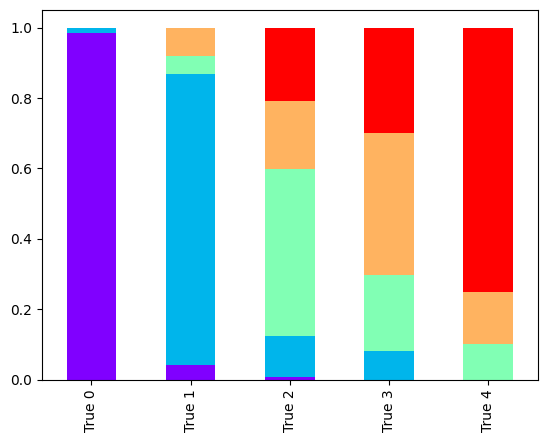

In [ ]:
#Fig. S16c
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix, classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.combine import SMOTETomek
import warnings
from xgboost import XGBClassifier
from collections import OrderedDict

param_xgb = OrderedDict([('colsample_bytree', 1.0), ('gamma', 1.0), ('learning_rate', 0.044467427955017326), ('max_depth', 4), ('n_estimators', 100), ('reg_alpha', 5.0), ('reg_lambda', 0.31039965058000984), ('subsample', 0.7128060642323459)])

pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=0)), 
    ('XGBoost',XGBClassifier(eval_metric='mlogloss', 
                            random_state=42, 
                            n_jobs=-1, **param_xgb)),])


cv = StratifiedKFold(n_splits=5,shuffle=True, random_state=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    y_proba = cross_val_predict(pipeline, X_reduced, y, cv=cv, method='predict_proba')
y_pred = [4 if prob[4] > 0.2 else np.argmax(prob) for prob in y_proba]
#y_pred = np.argmax(y_proba, axis=1)

accuracy = accuracy_score(y, y_pred)
macro_f1 = f1_score(y, y_pred, average='macro')
weighted_f1 = f1_score(y, y_pred, average='weighted')
balanced_acc = balanced_accuracy_score(y, y_pred)

conf_matrix = confusion_matrix(y, y_pred, labels=[0, 1, 2, 3, 4])
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
df = pd.DataFrame(conf_matrix_normalized, columns=[f'Pred {i}' for i in range(5)], index=[f'True {i}' for i in range(5)])
df.plot(kind='bar', stacked=True,  colormap="rainbow",legend=False)
plt.savefig('../result/figure.svg')


print(balanced_acc)

In [12]:
#Fig. S16b
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

results = []

for threshold in np.arange(0, 1.0001, 0.05):
    y_pred_t = np.array([
        4 if prob[4] > threshold else np.argmax(prob)
        for prob in y_proba
    ])

    y_true_4 = (np.asarray(y) == 4).astype(int)
    y_pred_4 = (y_pred_t == 4).astype(int)

    precision = precision_score(y_true_4, y_pred_4, zero_division=0)
    recall = recall_score(y_true_4, y_pred_4, zero_division=0)
    f1 = f1_score(y_true_4, y_pred_4, zero_division=0)
    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'N_predicted_class4': y_pred_4.sum()
    })

threshold_df = pd.DataFrame(results)
threshold_df['Threshold'] = threshold_df['Threshold'].round(2)

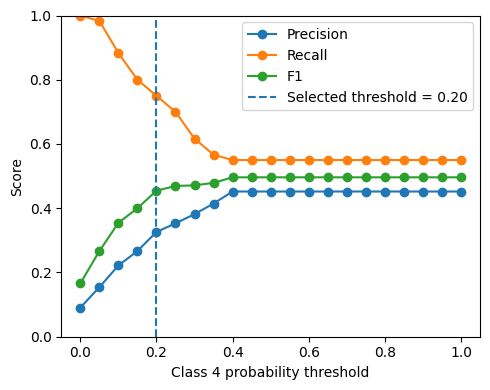

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 4))
plt.plot(threshold_df['Threshold'], threshold_df['Precision'], marker='o', label='Precision')
plt.plot(threshold_df['Threshold'], threshold_df['Recall'], marker='o', label='Recall')
plt.plot(threshold_df['Threshold'], threshold_df['F1'], marker='o', label='F1')
plt.axvline(0.2, linestyle='--', label='Selected threshold = 0.20')
plt.xlabel('Class 4 probability threshold')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig('../result/figure.svg')
plt.show()

### Patient classification (Fig. 6b)

In [10]:
import numpy as np
X_reduced = np.load("../data/X_reduced_clinical_260919.npy") #Expression + lineage
X_lineage = np.load("../data/X_lineage_clinical_260919.npy") #Lineage only
chosen_genes = np.load("../data/chosen_genes_clinical_260919.npy", allow_pickle=True)
y = np.load("../data/y_clinical_260919.npy")
lineage_cols = np.load("../data/lineage_cols.npy", allow_pickle=True)

In [19]:
#Main model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
from imblearn.pipeline import Pipeline
import pandas as pd
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from collections import OrderedDict

X_reduced = np.load("../data/X_reduced_clinical_260919.npy")
y = np.load("../data/y_clinical_260919.npy")
param_xgb = OrderedDict([('colsample_bytree', 1.0), ('gamma', 1.0), ('learning_rate', 0.044467427955017326), ('max_depth', 4), ('n_estimators', 100), ('reg_alpha', 5.0), ('reg_lambda', 0.31039965058000984), ('subsample', 0.7128060642323459)])

pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=0)), 
    ('XGBoost',XGBClassifier(eval_metric='mlogloss', 
                            random_state=42, 
                            n_jobs=-1, **param_xgb)),
])
pipeline.fit(X_reduced, y)

c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.w

Pipeline(steps=[('smote', SMOTETomek(random_state=0)),
                ('XGBoost',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=1.0, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric='mlogloss',
                               feature_types=None, gamma=1.0, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.044467427955017326, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=4,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])

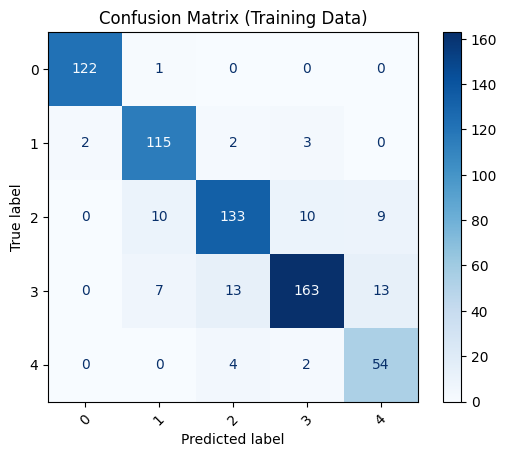

In [6]:
#Sanity check on training data
# Compute confusion matrix
cm = confusion_matrix(y, pipeline.predict(X_reduced), labels=np.unique(y))

# Display it
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y))
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix (Training Data)")
plt.show()

In [26]:
# Chunked prediction on large file
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
file_path = 'E:/TCGA alighned/Celligner_aligned_data.csv'
info = pd.read_csv("../data/Celligner_info.csv")
id_to_lineage = {id:lin for id, lin in zip(info["sampleID"], info["lineage"])}
id_to_subtype = {id:f'{lin}_{sub}' for id, lin, sub in zip(info["sampleID"], info["lineage"], info["subtype"])}

def custom_predict(clf, X):
    y_proba = clf.predict_proba(X) 
    y_pred = [4 if proba[4] > 0.2 else np.argmax(proba) for proba in y_proba]
    return np.array(y_pred)

chosen_genes = np.load("../data/chosen_genes_clinical_260919.npy", allow_pickle=True)
selected_gene_names = list(chosen_genes)
selected_gene_names_set = set(selected_gene_names)

file_cols = pd.read_csv(file_path, nrows=0).columns
index_col_name = file_cols[0] 
file_gene_cols_set = set(file_cols[1:])

cols_to_read = [index_col_name] + selected_gene_names

lineage_col_index = {col_name: i for i, col_name in enumerate(lineage_cols)}
results = []

print("Starting chunked prediction...")

# 6. Read the file in chunks using the correct column names
for chunk in tqdm(pd.read_csv(
    file_path,
    index_col=index_col_name,  # Use the *name* of the index column
    chunksize=1000,
    iterator=True,
    usecols=cols_to_read       # Read *both* index and selected genes
)):
    scaler = StandardScaler()  # Initialize the scaler
    X_gene_chunk = chunk[selected_gene_names].values
    X_gene_chunk = scaler.fit_transform(X_gene_chunk)
    X_lineage_chunk = np.zeros((len(chunk), len(lineage_cols)), dtype=int)

    for i, row_index in enumerate(chunk.index):
        lin = id_to_lineage.get(row_index)
        sub = id_to_subtype.get(row_index)

        if lin in lineage_col_index:
            col_idx = lineage_col_index[lin]
            X_lineage_chunk[i, col_idx] = 1

        if sub in lineage_col_index:
            col_idx = lineage_col_index[sub]
            X_lineage_chunk[i, col_idx] = 1

    # C. Combine gene and lineage features in the correct order
    X_chunk_reduced = np.hstack([X_gene_chunk, X_lineage_chunk])

    # --- Make predictions ---
    # Use the standard .predict() method
    y_pred = custom_predict(pipeline, X_chunk_reduced)
    #y_pred = pipeline.predict(X_chunk_reduced) 
    
    results.extend(zip(chunk.index, y_pred))

# 7. Create the final results DataFrame
results_df = pd.DataFrame(results, columns=['Index', 'Prediction'])

print("\nPrediction complete.")
print(results_df.head())

Starting chunked prediction...


14it [00:15,  1.07s/it]


Prediction complete.
                      Index  Prediction
0             TH27_1241_S01           0
1  TARGET-40-0A4I65-01A-01R           4
2            THR24_1965_S01           2
3            THR24_2080_S01           1
4            THR20_0494_S01           1


In [ ]:
#Fig. 6b
import matplotlib.pyplot as plt
import pandas as pd

# Ensure lineage and Prediction exist
results_df['lineage'] = results_df['Index'].map(id_to_lineage)

if 'lineage' not in results_df.columns or 'Prediction' not in results_df.columns:
    raise ValueError("Missing 'lineage' or 'Prediction' column in results_df")

# 1. Count predictions per lineage
counts = results_df.groupby(['lineage', 'Prediction']).size().unstack(fill_value=0)

# 2. Convert to proportions (optional)
proportions = counts.div(counts.sum(axis=1), axis=0)

# 3. Plot stacked bar chart
proportions.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='rainbow',
)
results_df.index = results_df['Index']

plt.ylabel('Proportion')
plt.xlabel('Lineage')
plt.title('Distribution of Predictions by Lineage')
plt.legend(title='Prediction', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../result/figure.svg')
plt.show()


In [ ]:
#results_df.to_csv('../data/patient_prediction.csv', index=False)

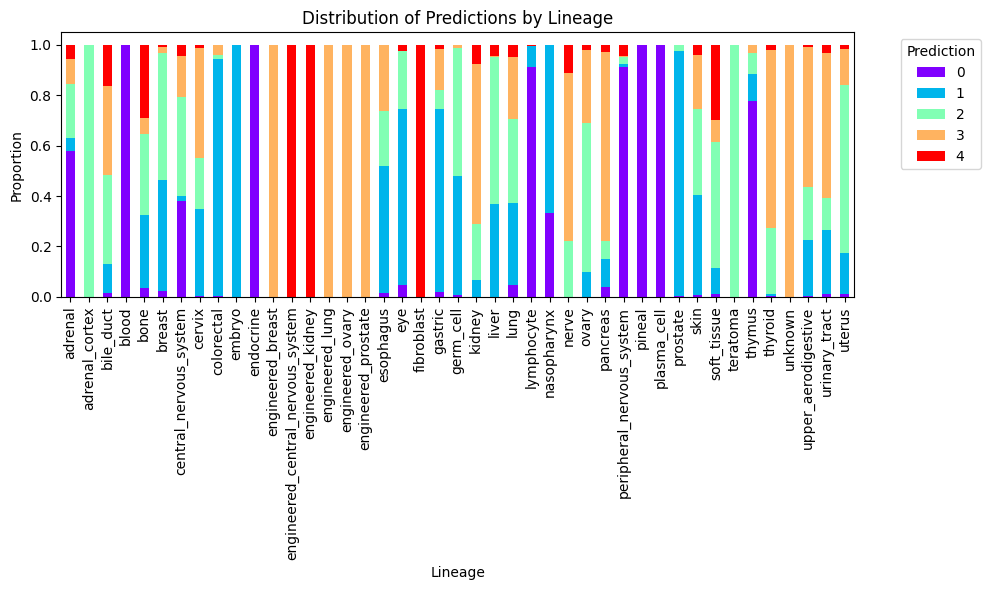

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
results_df = pd.read_csv("../data/patient_prediction.csv", index_col=0)
# 1. Count predictions per lineage
counts = results_df.groupby(['lineage', 'Prediction']).size().unstack(fill_value=0)

# 2. Convert to proportions (optional)
proportions = counts.div(counts.sum(axis=1), axis=0)

# 3. Plot stacked bar chart
proportions.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='rainbow',
)
#results_df.index = results_df['Index']

plt.ylabel('Proportion')
plt.xlabel('Lineage')
plt.title('Distribution of Predictions by Lineage')
plt.legend(title='Prediction', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../result/figure.svg')
plt.show()


In [18]:
df = proportions.copy()
name_map = {
    "adrenal": "Adrenal gland",
    "adrenal_cortex": "Adrenal gland",
    "bile_duct": "Biliary Tract",
    "central_nervous_system": "CNS/Brain",
    "colorectal": "Bowel",
    "gastric": "Stomach",
    #"nasopharynx": "Head and Neck",
    "upper_aerodigestive": "Head and Neck",
    "peripheral_nervous_system": "PNS",
    #"nerve": "PNS",
    "lymphocyte": "Lymphoid",
    #"plasma_cell": "Lymphoid",
    "soft_tissue": "Soft Tissue",
    "germ_cell": "Germ Cell"
}
df.index = df.index.map(lambda x: name_map.get(x, ''))
df.index.name = "Tumor sample"
df[df.index != '']


Prediction,0,1,2,3,4
Tumor sample,,,,,
Adrenal gland,0.577061,0.053763,0.215054,0.096774,0.057348
Adrenal gland,0.000000,0.000000,1.000000,0.000000,0.000000
Biliary Tract,0.014706,0.117647,0.352941,0.352941,0.161765
CNS/Brain,0.379045,0.022342,0.392142,0.162558,0.043914
Bowel,0.002227,0.942094,0.015590,0.037862,0.002227
Stomach,0.017354,0.726681,0.078091,0.162690,0.015184
Germ Cell,0.006410,0.474359,0.506410,0.012821,0.000000
Lymphoid,0.912281,0.081871,0.000000,0.000000,0.005848
PNS,0.912621,0.009709,0.029126,0.004854,0.043689


### Marker (Fig. 6h, i, S17g)

In [19]:
file_path = 'E:/TCGA alighned/Celligner_aligned_data.csv'
#Download from https://figshare.com/articles/dataset/Celligner_data/11965269/4

all = pd.read_csv(file_path,index_col=0)
results_df = pd.read_csv("../data/patient_prediction.csv", index_col=0)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

cluster = results_df["Prediction"].to_numpy()

valid = (cluster == 4) | (cluster < 3)

X = all.loc[valid].reset_index(drop=True)
y = (cluster[valid] == 4).astype(int)

X_discovery, X_validation, y_discovery, y_validation = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Discovery:", len(y_discovery), "Class 4:", y_discovery.sum())
print("Validation:", len(y_validation), "Class 4:", y_validation.sum())

Discovery: 8335 Class 4: 515
Validation: 2084 Class 4: 129


In [44]:
auroc_scores_discovery = X_discovery.apply(
    lambda col: roc_auc_score(y_discovery, col) if col.nunique() > 1 else 0
)

auroc_df_discovery = auroc_scores_discovery.reset_index()
auroc_df_discovery.columns = ["Column", "AUROC"]
auroc_df_discovery = auroc_df_discovery.sort_values("AUROC", ascending=False)

print(auroc_df_discovery.head(20))



                Column     AUROC
7915   ENSG00000150093  0.956359
8740   ENSG00000100097  0.945990
10645  ENSG00000166741  0.941637
8886   ENSG00000134013  0.940710
1463   ENSG00000176697  0.938959
1317   ENSG00000167601  0.934208
6512   ENSG00000164294  0.933074
3363   ENSG00000142173  0.928010
3362   ENSG00000142156  0.924884
14016  ENSG00000126458  0.924425
6206   ENSG00000139278  0.920229
15929  ENSG00000105137  0.918153
8883   ENSG00000113083  0.917544
4870   ENSG00000142227  0.916402
7632   ENSG00000166130  0.915996
14467  ENSG00000106366  0.914979
16362  ENSG00000120708  0.911923
12344  ENSG00000152952  0.908456
5829   ENSG00000163430  0.906991
2185   ENSG00000128595  0.906515


In [46]:
import requests
r = requests.post(
    url='https://biit.cs.ut.ee/gprofiler/api/convert/convert/',
    json={'organism':'hsapiens','target':'HGNC','query':auroc_df_discovery.Column.tolist()[:20]}).json()['result']
gene_mapping = {item['incoming']: item['converted'] for item in r}

#for gene in auroc_df_discovery.Column.tolist()[:20]:
resdict = {}
for gene in auroc_df_discovery.Column.tolist()[:20]:

    gene_hgnc = gene_mapping.get(gene, gene)
    auc_discovery = roc_auc_score(y_discovery, X_discovery[gene])
    auc_validation = roc_auc_score(y_validation, X_validation[gene])
    #print(f"{gene} AUROC - Discovery:", auc_discovery)
    print(f"{gene_hgnc} - discovery vs validation:", auc_discovery, auc_validation)

    resdict[gene_hgnc] = {
        "AUROC_Discovery": auc_discovery,
        "AUROC_Validation": auc_validation
    }


ITGB1 - discovery vs validation: 0.9563590991483127 0.9542853744126568
LGALS1 - discovery vs validation: 0.9459898691430983 0.9261285909712722
NNMT - discovery vs validation: 0.9416370769498175 0.9293205654354766
LOXL2 - discovery vs validation: 0.9407096565937476 0.9332817859196256
BDNF - discovery vs validation: 0.938958855809103 0.9348163127738456
AXL - discovery vs validation: 0.9342080301939263 0.9315014175538769
GPX8 - discovery vs validation: 0.93307364735679 0.8992287713872202
COL6A2 - discovery vs validation: 0.9280095845852062 0.9247050893158072
COL6A1 - discovery vs validation: 0.9248836689593525 0.9081068221019448
RRAS - discovery vs validation: 0.9244250490403 0.918531295227899
GLIPR1 - discovery vs validation: 0.9202294341121843 0.9112075972957434
SYDE1 - discovery vs validation: 0.9181534775159536 0.9147841947699201
LOX - discovery vs validation: 0.9175442604226155 0.9042764527448999
EMP3 - discovery vs validation: 0.9164024284259926 0.8871032336089139
IKBIP - discovery 

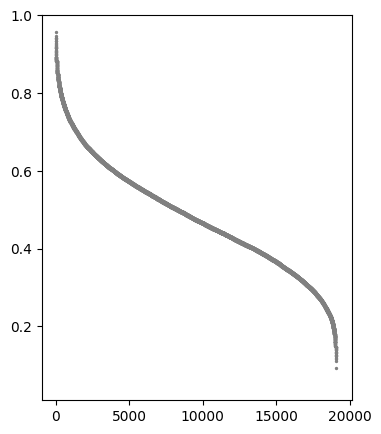

In [39]:
#Fig. 6h
plt.figure(figsize=(4, 5))

plt.ylim((0.01,1))
plt.scatter(range(len(auroc_df_discovery)), auroc_df_discovery["AUROC"], s=2, c='gray')
plt.savefig('../result/figure.svg')


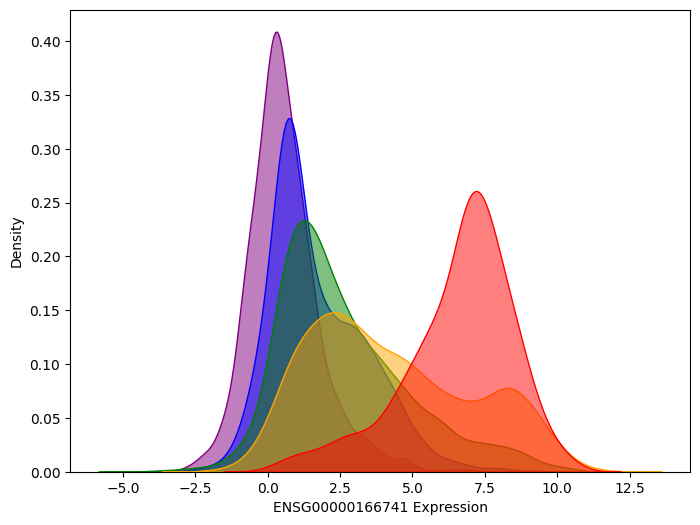

In [ ]:
#Fig. 6i, S17g
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

#geneid = 'ENSG00000150093' #ITGB1
geneid = 'ENSG00000166741' #NNMT
df2 = all[[geneid]].copy()

df2["Cluster"]=cluster

colors = ["purple", "blue", "green", "orange", "red"]
g= geneid
#g = 'ENSG00000150093'
plt.figure(figsize=(8,6))
for i, color in enumerate(colors):
    sns.kdeplot(df2[df2["Cluster"] == i][g], color=color, label=f"Cluster {i}", fill=True, alpha=0.5)

plt.xlabel(f"{geneid} Expression")
plt.ylabel("Density")
#plt.xlim((-2,6))
#plt.ylim(0, 0.5)  
plt.savefig("../result/figure.svg", bbox_inches='tight', pad_inches=0, dpi=300)

plt.show()



In [43]:
a = all[['ITGB1','NNMT']].merge(results_df, left_index=True, right_index=True).copy()
a = a[['ITGB1','NNMT','Prediction']]
clusters = ['YAP-off','YAP-target-low','Hippo-weak','Hippo-middle','Hippo-strong']
a['Prediction'] = [clusters[i] for i in a['Prediction']]
a.to_csv('../others/source.csv')

In [23]:
import requests
r = requests.post(
    url='https://biit.cs.ut.ee/gprofiler/api/convert/convert/',
    json={'organism':'hsapiens','target':'HGNC','query':all.columns.tolist()}).json()['result']
gene_mapping = {item['incoming']: item['converted'] for item in r}


In [24]:
all.columns = [gene_mapping.get(col, col) for col in all.columns]
all.head()

,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,AACS,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
TH27_1241_S01,8.723329,-0.744151,-0.970048,-0.940143,-0.648609,-0.914330,-0.474306,-0.350996,1.291482,0.284951,...,-0.503157,-1.475805,0.108935,-0.893518,-0.825525,3.075079,0.887402,0.053549,1.667489,-0.251755
TARGET-40-0A4I65-01A-01R,3.008313,-1.176801,2.770918,-0.698398,-0.298889,1.556312,-0.453067,0.122412,1.792169,0.224788,...,-0.248255,-0.485090,1.761130,1.506456,-1.182720,0.969696,1.069500,2.900110,0.242608,0.352725
THR24_1965_S01,8.500339,-1.563082,7.481716,-1.037960,-0.339852,-2.827530,-0.249633,0.065161,1.904344,0.164516,...,-1.063764,-0.778230,0.013762,-1.125371,-0.723234,1.084220,0.089596,2.280495,1.717596,0.384248
THR24_2080_S01,6.942271,-1.287777,5.241823,-0.729905,-0.318868,-2.429765,-0.378474,0.149241,1.055385,0.176362,...,-0.525339,-0.866752,-0.374140,-1.656769,-0.974324,1.117792,0.324915,1.979401,1.055527,0.345921
THR20_0494_S01,7.357766,-0.781635,-1.407421,-0.470331,-0.637489,-3.105987,-0.439940,0.468221,1.573491,0.279335,...,-1.444808,-0.195967,0.200123,-1.017149,-0.596055,2.723937,0.483434,1.107530,1.419093,-0.129675


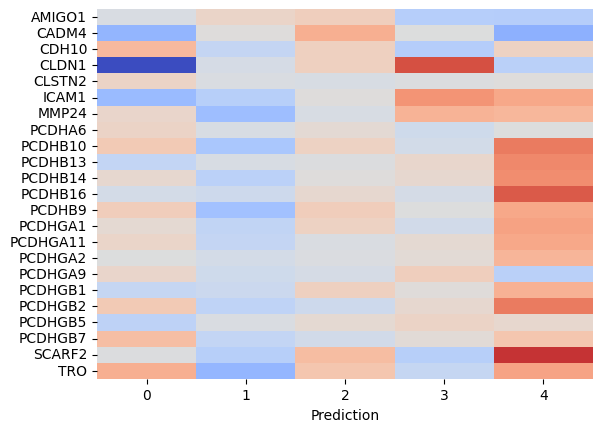

In [36]:
genes_down ="""AMIGO1
CADM4
CDH10
CLDN1
CLSTN2
ICAM1
MMP24
PCDHA6
PCDHB10
PCDHB13
PCDHB14
PCDHB16
PCDHB9
PCDHGA1
PCDHGA11
PCDHGA2
PCDHGA9
PCDHGB1
PCDHGB2
PCDHGB5
PCDHGB7
SCARF2
TRO""".strip().split()

all2 = all[genes_down].copy()
all2 = all2.merge(results_df, left_index=True, right_index=True)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
all2[genes_down] = StandardScaler().fit_transform(all2[genes_down])
a = all2.groupby("Prediction")[genes_down].mean().T
#a = pd.DataFrame(StandardScaler().fit_transform(a)).T

sns.heatmap(a, cmap="coolwarm", vmin=-1,vmax=1,cbar=False)
plt.savefig('../result/figure.svg')
plt.show()

In [35]:
a.index = genes_down
a

Prediction,0,1,2,3,4
AMIGO1,-0.031590,0.115300,0.170021,-0.258116,-0.269407
CADM4,-0.463875,0.015587,0.385068,-0.004666,-0.495800
CDH10,0.327634,-0.176674,0.149205,-0.271547,0.139863
CLDN1,-1.081133,-0.060203,0.152946,0.812146,-0.235978
CLSTN2,0.118925,-0.026281,-0.045471,-0.013227,0.011164
ICAM1,-0.426060,-0.252863,0.015450,0.531197,0.427934
MMP24,0.095833,-0.399639,-0.042771,0.366411,0.341946
PCDHA6,0.123080,-0.046361,0.048190,-0.103839,-0.003942
PCDHB10,0.206115,-0.331950,0.134734,-0.078876,0.634878
PCDHB13,-0.180892,-0.043061,-0.014643,0.093213,0.578679


### Model without NNMT and ITGB1

In [50]:
X_reduced = np.load("../data/X_reduced_clinical_260919.npy")
X_lineage = np.load("../data/X_lineage_clinical_260919.npy")
chosen_genes = np.load("../data/chosen_genes_clinical_260919.npy", allow_pickle=True)
y = np.load("../data/y_clinical_260919.npy")
lineage_cols = np.load("../data/lineage_cols.npy", allow_pickle=True)

print('ITGB1', np.where(chosen_genes == "ENSG00000150093")[0])
print('NNMT', np.where(chosen_genes == "ENSG00000166741")[0])


ITGB1 [103]
NNMT [129]


In [91]:
#Model without NNMT and ITGB1
#Main model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from collections import OrderedDict
import pandas as pd
X_reduced = np.load("../data/X_reduced_clinical_260919.npy")

X_reduced = np.delete(X_reduced, [105, 129], axis=1)

param_xgb = OrderedDict([('colsample_bytree', 1.0), ('gamma', 1.0), ('learning_rate', 0.044467427955017326), ('max_depth', 4), ('n_estimators', 100), ('reg_alpha', 5.0), ('reg_lambda', 0.31039965058000984), ('subsample', 0.7128060642323459)])

pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=0)), 
    ('XGBoost',XGBClassifier(eval_metric='mlogloss', 
                            random_state=42, 
                            n_jobs=-1, **param_xgb)),
])
pipeline.fit(X_reduced, y)


c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\ki949\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.w

Pipeline(steps=[('smote', SMOTETomek(random_state=0)),
                ('XGBoost',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=1.0, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric='mlogloss',
                               feature_types=None, gamma=1.0, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.044467427955017326, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=4,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])

In [92]:
# Chunked prediction on large file
import pandas as pd
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
file_path = 'E:/TCGA alighned/Celligner_aligned_data.csv'

def custom_predict(clf, X):
    y_proba = clf.predict_proba(X)  # 予測確率を取得
    y_pred = [4 if proba[4] > 0.2 else np.argmax(proba) for proba in y_proba]
    return np.array(y_pred)

chosen_genes_noITGB1_noNNMT = [gene for gene in chosen_genes if gene not in ['ENSG00000150093', 'ENSG00000166741']]
selected_gene_names = chosen_genes_noITGB1_noNNMT
selected_gene_names_set = set(selected_gene_names)

file_cols = pd.read_csv(file_path, nrows=0).columns
index_col_name = file_cols[0] 
file_gene_cols_set = set(file_cols[1:])

cols_to_read = [index_col_name] + selected_gene_names
lineage_col_index = {col_name: i for i, col_name in enumerate(lineage_cols)}
results = []

print("Starting chunked prediction...")
for chunk in tqdm(pd.read_csv(file_path,index_col=index_col_name, 
    iterator=True,usecols=cols_to_read, chunksize=1000)):

    X_gene_chunk = chunk[selected_gene_names].values
    X_gene_chunk = StandardScaler().fit_transform(X_gene_chunk)
    X_lineage_chunk = np.zeros((len(chunk), len(lineage_cols)), dtype=int)
    for i, row_index in enumerate(chunk.index):
        lin = id_to_lineage.get(row_index)
        sub = id_to_subtype.get(row_index)

        if lin in lineage_col_index:
            col_idx = lineage_col_index[lin]
            X_lineage_chunk[i, col_idx] = 1

        if sub in lineage_col_index:
            col_idx = lineage_col_index[sub]
            X_lineage_chunk[i, col_idx] = 1

    X_chunk_reduced = np.hstack([X_gene_chunk, X_lineage_chunk])

    y_pred = custom_predict(pipeline, X_chunk_reduced)
    results.extend(zip(chunk.index, y_pred))

# 7. Create the final results DataFrame
results_df = pd.DataFrame(results, columns=['Index', 'Prediction'])

print("\nPrediction complete.")
print(results_df.head())

Starting chunked prediction...


14it [00:38,  2.78s/it]


Prediction complete.
                      Index  Prediction
0             TH27_1241_S01           0
1  TARGET-40-0A4I65-01A-01R           4
2            THR24_1965_S01           3
3            THR24_2080_S01           1
4            THR20_0494_S01           1


In [96]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

cluster = np.array(results_df["Prediction"].tolist())
valid = (cluster == 4) | (cluster < 3)
X = all.loc[valid].reset_index(drop=True)
y = (cluster[valid] == 4).astype(int)

auc_ = roc_auc_score(y, X['ENSG00000166741'])
print(f"NNMT:", auc_)

auc_ = roc_auc_score(y, X['ENSG00000150093'])
print(f"ITGB1:", auc_)

NNMT: 0.9244293220634532
ITGB1: 0.8889998438776743
